In [2]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import os
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import plotly.express as px
from datetime import datetime

sys.path.append("..")

# Get data

In [3]:
path = Path(r"..\data\features\features_lpc_filtered_seq1.csv")

In [4]:
raw_feat = pd.read_csv(path)

In [5]:
raw_feat["sampled_at"] = raw_feat["sampled_at"].apply(datetime.fromisoformat)

In [6]:
raw_feat = raw_feat.loc[raw_feat["sampled_at"] > datetime(2023,1,1)].reset_index().copy() # for seq1 we need to add this filter

# Extract features

In [7]:
raw_feat["abs"] = raw_feat.apply(
    lambda x: [
        np.sqrt(r**2 + i**2)
        for r, i in zip(json.loads(x["reals"]), json.loads(x["imags"]))
    ],
    axis=1,
)

In [36]:
def get_percentile_features(raw_data: str) -> dict:
    x = json.loads(raw_data)
    feats = {
        f"p{i}": float(np.percentile(x, i)) for i in np.arange(10,100,20)
    }
    x_array = np.array(x)
    feats.update({"mean": float(np.mean(x_array[x_array<25]))})
    return feats

In [37]:
def get_hist_features(raw_data: str, n_bins: int) -> dict:
    x = json.loads(raw_data)
    freq, bins = np.histogram(x, bins=np.linspace(0, 64, n_bins))
    return {f"b{k}": val for k, val in enumerate(freq)}

In [38]:
def get_distance(a: complex, b: complex) -> float:
    return abs(a - b)

In [39]:
feats = raw_feat["frequencies"].apply(lambda x: get_percentile_features(x))

In [40]:
feats_df = pd.json_normalize(feats)

In [41]:
feats_view = pd.concat((raw_feat[["sampled_at", "cable", "axis", "tension"]], feats_df), axis=1)

In [42]:
feats_names = [x for x in feats_view.columns if x not in ["sampled_at", "cable", "axis", "tension"]]

# Visualization

In [54]:
# for cable in ["c1", "c2", "c3", "c4"]:
#     for ax in ["x", "y", "z"]:
#         data = feats_view.loc[(feats_view["axis"]==ax) & (feats_view["cable"]==cable)].sort_values("sampled_at", ascending=True)
#         plt.figure(figsize=(10,4))
#         plt.subplot(1,2,1)
#         plt.pcolormesh(data["sampled_at"], feats_names, data[feats_names].to_numpy().T)
#         plt.subplot(1,2,2)
#         data = feats_view.loc[(feats_view["axis"]==ax) & (feats_view["cable"]==cable)].sort_values("tension", ascending=True)
#         plt.pcolormesh(data["tension"], feats_names, data[feats_names].to_numpy().T)

In [44]:
def plot_circle(semi: bool = False):
    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)
    circ = plt.Circle((0, 0), radius=1, edgecolor='gray', facecolor='None')
    ax.add_patch(circ)
    # ax.set_aspect('equal', 'box')
    if semi:
        plt.ylim(bottom=0)

In [45]:
def get_colors_from_cmap(cmap_name, N):
    """
    Return N colors sampled continuously from a Matplotlib colormap.
    
    Parameters:
    - cmap_name (str): Name of the Matplotlib colormap (e.g., 'viridis', 'plasma').
    - N (int): Number of colors to return.
    
    Returns:
    - List of RGB tuples, each representing a color.
    """
    # Get the colormap
    cmap = plt.get_cmap(cmap_name)
    
    # Sample colors from the colormap
    colors = [cmap(i / (N - 1)) for i in range(N)]
    
    return colors

In [46]:
def plot_poles(reals: list[float], imags: list[float], color): 
    for r, i in zip(json.loads(reals), json.loads(imags)):
        plt.scatter(r, i, marker="x", color=color, alpha=0.6)

In [47]:
healthy_date_limit = datetime(2023,1,26)

In [58]:
healthy_feats = raw_feat.loc[raw_feat["sampled_at"]<=healthy_date_limit].reset_index(drop=True)

In [48]:
cable = "c1"
axis = "y"
healthy_samples = 50

healthy = (
    feats_view.loc[
        (feats_view["axis"] == axis)
        & (feats_view["cable"] == cable)
        & (feats_view["sampled_at"] < healthy_date_limit)
    ]
    .sample(healthy_samples)
    .reset_index()
    .sort_values("sampled_at", ascending=True)
)

unhealthy_samples = 200
unhealthy = (
    feats_view.loc[
        (feats_view["axis"] == axis)
        & (feats_view["cable"] == cable)
        & (feats_view["sampled_at"] > healthy_date_limit)
    ]
    .sample(unhealthy_samples)
    .reset_index()
    .sort_values("sampled_at", ascending=True)
)
colors = get_colors_from_cmap("jet", unhealthy_samples)

In [49]:
unhealthy['week'] = unhealthy['sampled_at'].dt.isocalendar().week

In [50]:
# plot_circle(True)
# for i, row in healthy.iterrows():
#     plot_poles(**row[["reals", "imags"]].to_dict(), color="k")

# week_colors = {k: i for i, k in enumerate(unhealthy['week'].unique())}
# colors = get_colors_from_cmap("jet", len(week_colors))

# for i, row in unhealthy.iterrows():
#     plot_poles(**row[["reals", "imags"]].to_dict(), color=colors[week_colors[row["week"]]])

# Fit model

In [51]:
feats_view.columns

Index(['sampled_at', 'cable', 'axis', 'tension', 'p10', 'p30', 'p50', 'p70',
       'p90', 'mean'],
      dtype='object')

In [52]:
px.line(feats_view.sort_values("tension"), x="tension", y="mean", facet_row="cable", facet_col="axis")

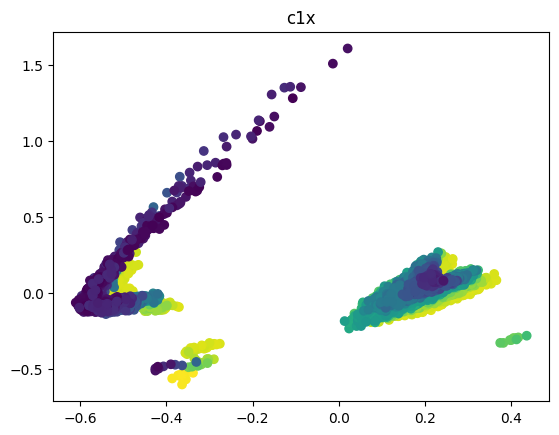

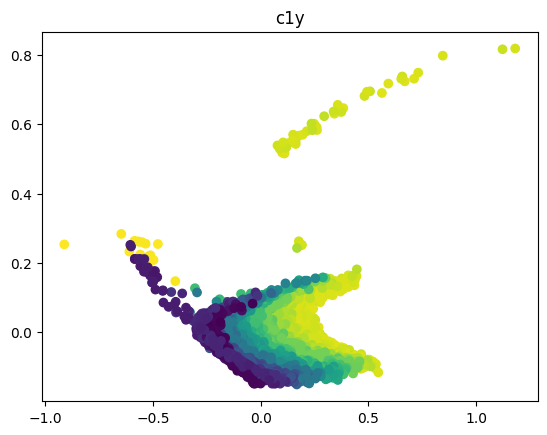

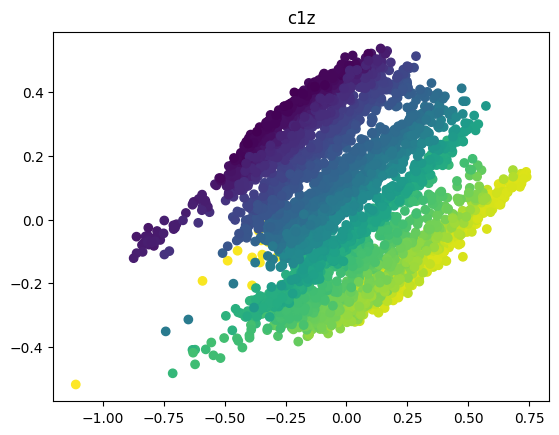

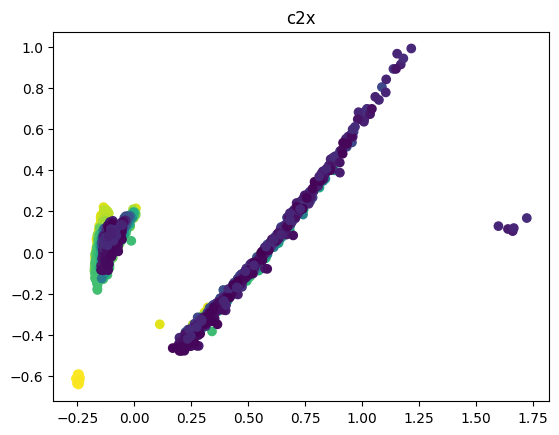

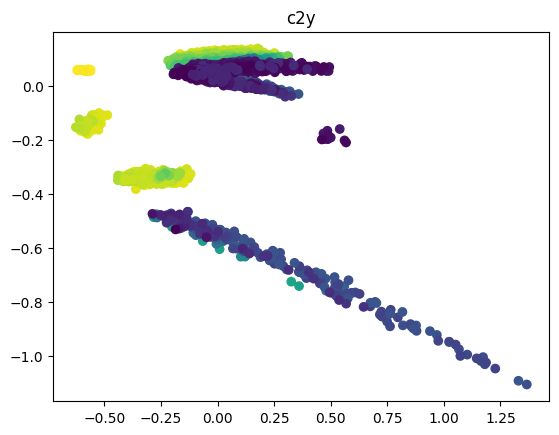

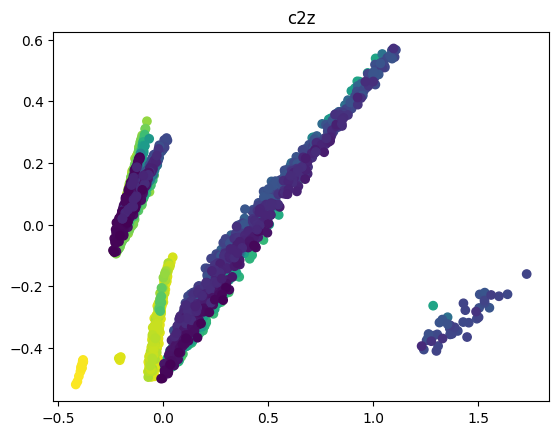

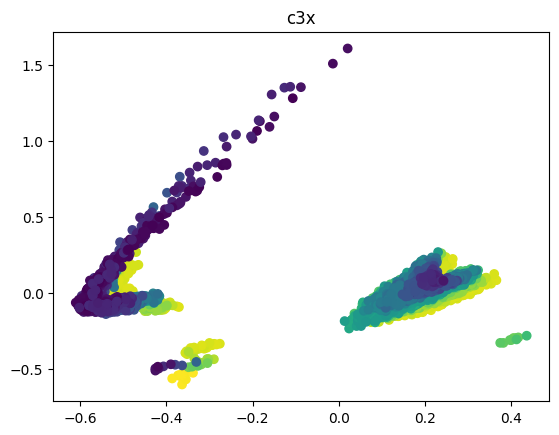

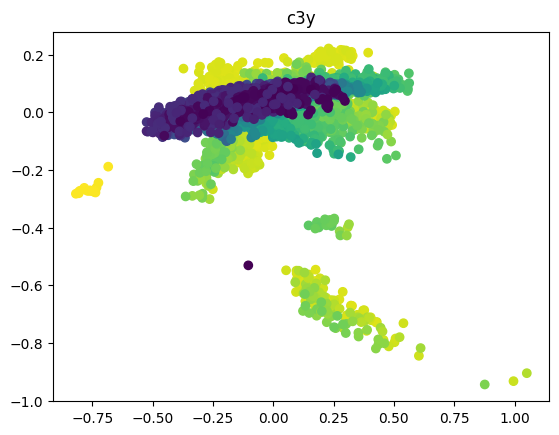

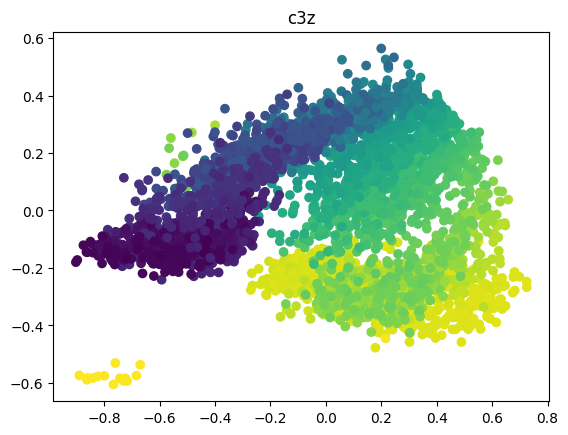

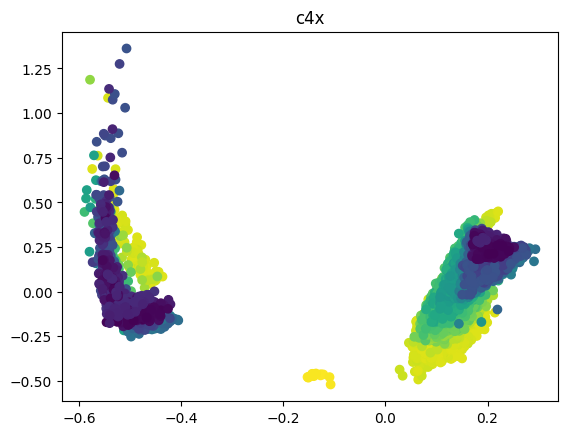

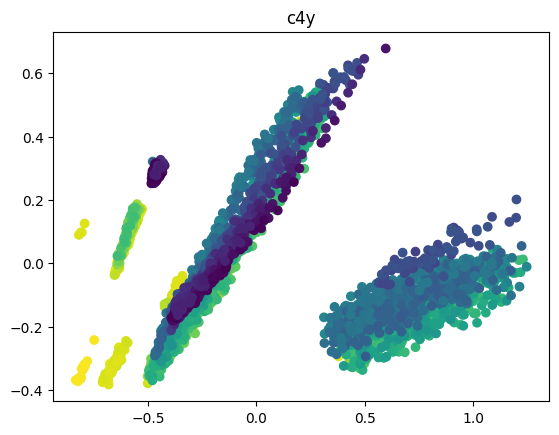

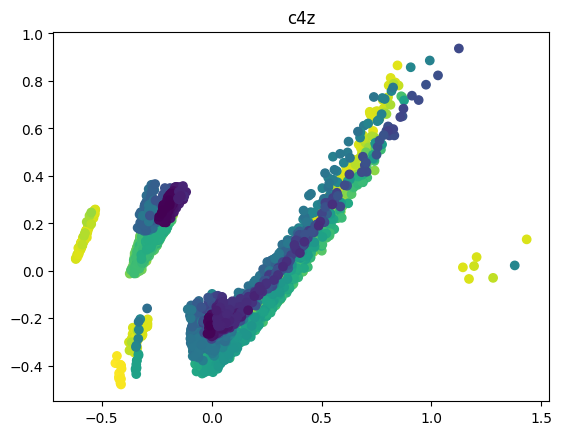

In [53]:
models = {}
features = feats_names
results = {}
data = {}
for id, df in feats_view.groupby(["cable", "axis"]):
    id_str = "".join(id)   
    pipe = Pipeline([("scale", MinMaxScaler()), ("pca", PCA(n_components=2))])
    pipe.fit(df[features])
    models[id_str] = pipe
    results[id_str] = pipe.transform(df[features])
    data[id_str] = df
    plt.figure()
    plt.title(f"{id_str}")
    plt.scatter(results[id_str][:,0], results[id_str][:,1], c=df["tension"])